# 03 · How robust is the network?

Week 3 removes stops (or whole routes) from the LBT graph and measures what's left.

**Metrics** (`transitshock.metrics.evaluate`), all measured against the original set of stops:
- **Efficiency:** the average of 1 / travel time over every ordered pair of stops, counting unreachable pairs as 0. It drops when trips get slower *or* impossible.
- **Reachable share:** the fraction of stop pairs that can still reach each other.
- **Largest strongly connected component (LSCC) share:** the biggest group of stops that can all reach one another.

**Attack strategies** (`transitshock.simulate`): remove the top-k stops ranked by
- **random:** random failures, averaged over 10 runs
- **degree:** number of direct connections
- **trips_per_day:** busiest stops
- **betweenness:** stops on the most fastest-paths

*Static* attacks rank once on the intact graph. *Adaptive* attacks re-rank after each round of removals.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from transitshock.build_graph import build_graph, graph_summary, load_graph
from transitshock.load_gtfs import load_feed
from transitshock.metrics import evaluate, to_matrix
from transitshock.simulate import attack_curve, rank_nodes, random_curves, route_outages

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

G = load_graph(PROCESSED / "lbt_20261104.gpickle")
FRACTIONS = np.round(np.arange(0, 0.31, 0.02), 2).tolist()
COLORS = {"random": "gray", "degree": "#1f77b4", "trips_per_day": "#2ca02c", "betweenness": "#D62028"}

_, matrix = to_matrix(G)
pd.Series(evaluate(matrix)).round(5)

efficiency          0.00084
reachable_share     1.00000
mean_time_min      29.08203
lscc_share          1.00000
dtype: float64

## 1. Static attacks

How fast does the network fall apart as the top stops are removed under each ranking?

In [2]:
%%time
curves = pd.concat(
    [random_curves(G, FRACTIONS, seeds=range(10))]
    + [attack_curve(G, s, FRACTIONS) for s in ["degree", "trips_per_day", "betweenness"]],
    ignore_index=True,
)
curves.to_csv(PROCESSED / "lbt_attack_curves.csv", index=False)

CPU times: user 29.8 s, sys: 70.4 ms, total: 29.9 s
Wall time: 3min 18s


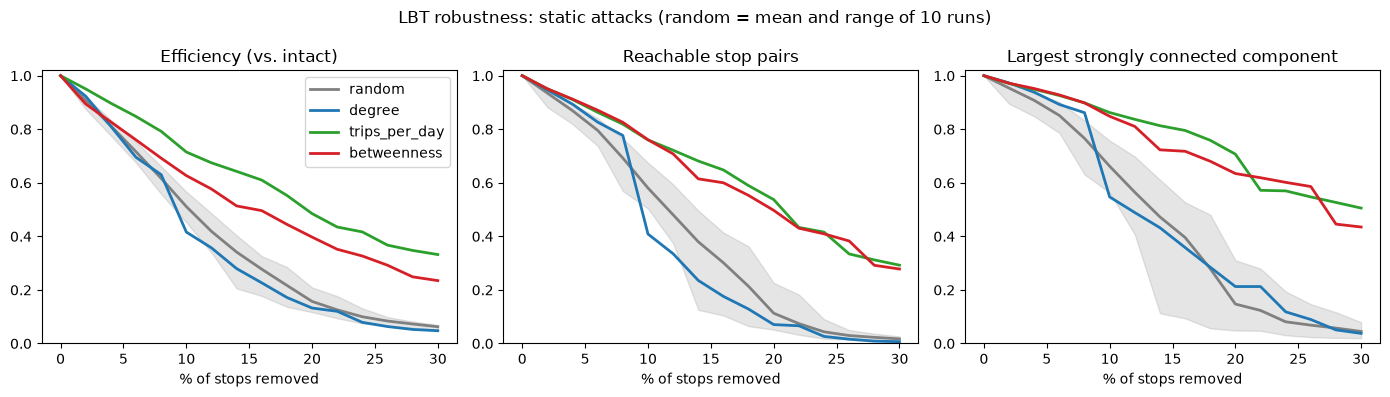

In [3]:
METRICS = {"efficiency_rel": "Efficiency (vs. intact)",
           "reachable_share": "Reachable stop pairs",
           "lscc_share": "Largest strongly connected component"}

def plot_curves(curves, title, path=None):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
    for ax, (metric, label) in zip(axes, METRICS.items()):
        for strategy, df in curves.groupby("strategy", sort=False):
            stats = df.groupby("fraction")[metric].agg(["mean", "min", "max"])
            ax.plot(stats.index * 100, stats["mean"], label=strategy, color=COLORS.get(strategy), lw=2)
            if df["seed"].nunique() > 1:
                ax.fill_between(stats.index * 100, stats["min"], stats["max"], color=COLORS.get(strategy), alpha=0.2)
        ax.set(title=label, xlabel="% of stops removed", ylim=(0, 1.02))
    axes[0].legend()
    fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)

plot_curves(curves, "LBT robustness: static attacks (random = mean and range of 10 runs)",
            FIGURES / "lbt_robustness_curves.png")

In [4]:
def fraction_to_reach(df, metric="efficiency_rel", level=0.5):
    """Smallest % of stops removed at which `metric` drops to `level` or below (interpolated)."""
    s = df.groupby("fraction")[metric].mean()
    below = s[s <= level]
    if below.empty:
        return np.nan
    hi = below.index[0]
    lo = s.index[s.index.get_loc(hi) - 1]
    return 100 * np.interp(level, [s[hi], s[lo]], [hi, lo])

summary = pd.DataFrame({
    strategy: {
        "% removed to halve efficiency": fraction_to_reach(df),
        "% removed to halve reachable pairs": fraction_to_reach(df, "reachable_share"),
        "efficiency left at 4% removed": df.loc[df["fraction"] == 0.04, "efficiency_rel"].mean(),
        "efficiency left at 10% removed": df.loc[df["fraction"] == 0.1, "efficiency_rel"].mean(),
    }
    for strategy, df in curves.groupby("strategy", sort=False)
}).T.round(2)
summary

,% removed to halve efficiency,% removed to halve reachable pairs,efficiency left at 4% removed,efficiency left at 10% removed
random,10.24,11.61,0.81,0.51
degree,9.22,9.50,0.81,0.42
trips_per_day,19.56,20.72,0.90,0.71
betweenness,15.56,19.90,0.83,0.63


In [5]:
# Which stops does each targeted strategy hit first?
first_hits = pd.DataFrame({
    s: [G.nodes[n]["name"] for n in rank_nodes(G, s)[:10]]
    for s in ["degree", "trips_per_day", "betweenness"]
}, index=range(1, 11))
first_hits

,degree,trips_per_day,betweenness
1,1st & Shelter B N,Beach Dr & W Campus N,Cherry & Wardlow SW
2,1st & Shelter C N,1st & Shelter G S,Del Amo & Orange SW
3,1st & Shelter G S,Artesia Station Bay 3,Cherry & 33rd SW
4,1st & Shelter H S,Long Beach Blvd & 3rd SE,Cherry & Spring NE
5,1st & Long Beach Blvd NE,7th & Channel SE,Cherry & 33rd SE
6,1st & Shelter F S,W Campus & Library East Side,Wardlow Station Bay 3
7,1st & Shelter D N,Beach Dr & Dorms N,Del Amo & Atlantic SE
8,Ocean & Pine SE,1st & Shelter H S,Cherry & Wardlow NE
9,Ocean & Long Beach NW,Pacific & 3rd SW,Cherry & 36th NE
10,Ocean & Pine NE,Ocean & Hart Pl SE,Cherry & 37th E


## 2. Adaptive vs. static betweenness

Once a critical stop is gone, traffic reroutes and *new* stops become critical. An adaptive attacker re-ranks after every 2% of stops removed.

CPU times: user 52 s, sys: 273 ms, total: 52.2 s
Wall time: 5min 16s


fraction,0.00,0.02,0.04,0.06,0.08,0.10,0.12,0.14,0.16,0.18,0.20
static,1.0,0.894,0.827,0.76,0.692,0.627,0.577,0.514,0.496,0.445,0.397
adaptive,1.0,0.894,0.799,0.67,0.602,0.447,0.385,0.338,0.285,0.246,0.205


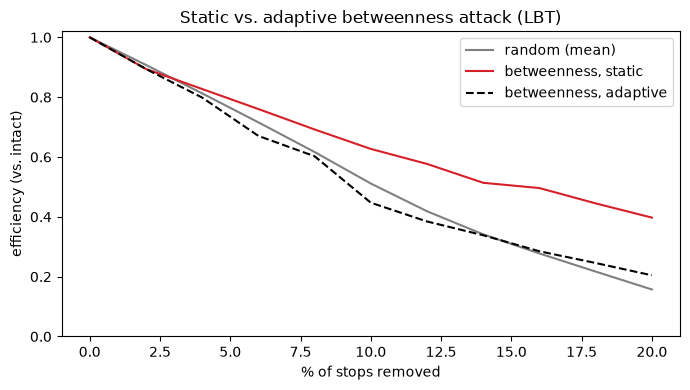

In [6]:
%%time
ADAPTIVE_FRACTIONS = [f for f in FRACTIONS if f <= 0.2]
adaptive = attack_curve(G, "betweenness", ADAPTIVE_FRACTIONS, adaptive=True)
static = curves[(curves["strategy"] == "betweenness") & (curves["fraction"] <= 0.2)]
random_mean = curves[(curves["strategy"] == "random") & (curves["fraction"] <= 0.2)].groupby("fraction")["efficiency_rel"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(random_mean.index * 100, random_mean.values, color="gray", label="random (mean)")
ax.plot(static["fraction"] * 100, static["efficiency_rel"], color="#D62028", label="betweenness, static")
ax.plot(adaptive["fraction"] * 100, adaptive["efficiency_rel"], color="black", ls="--", label="betweenness, adaptive")
ax.set(title="Static vs. adaptive betweenness attack (LBT)", xlabel="% of stops removed",
       ylabel="efficiency (vs. intact)", ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "lbt_adaptive_attack.png", dpi=150)
pd.DataFrame({"static": static.set_index("fraction")["efficiency_rel"],
              "adaptive": adaptive.set_index("fraction")["efficiency_rel"]}).round(3).T

## 3. Route outages

What if one line stops running? Each route's stops stay open (riders can walk or take other routes), but the segments only that route serves disappear.

In [7]:
%%time
outages = route_outages(G)
outages.to_csv(PROCESSED / "lbt_route_outages.csv", index=False)
outages.head(10).round(4)

CPU times: user 9.04 s, sys: 17.5 ms, total: 9.06 s
Wall time: 1min 23s


,route,edges_removed,efficiency_rel,reachable_share,mean_time_min,added_min
0,71,110,0.9237,0.9269,29.3513,0.2693
1,92,60,0.9496,0.9520,29.2446,0.1626
2,51,64,0.9506,0.9520,29.3181,0.2361
3,22,69,0.9511,0.9489,29.0868,0.0047
4,173,69,0.9540,0.9473,28.9958,-0.0862
5,172,59,0.9553,0.9552,29.1724,0.0904
6,191,65,0.9557,0.9658,29.5252,0.4432
7,21,56,0.9570,0.9563,29.2118,0.1298
8,131,54,0.9577,0.9796,29.8251,0.7431
9,104,59,0.9578,0.9668,29.3675,0.2854


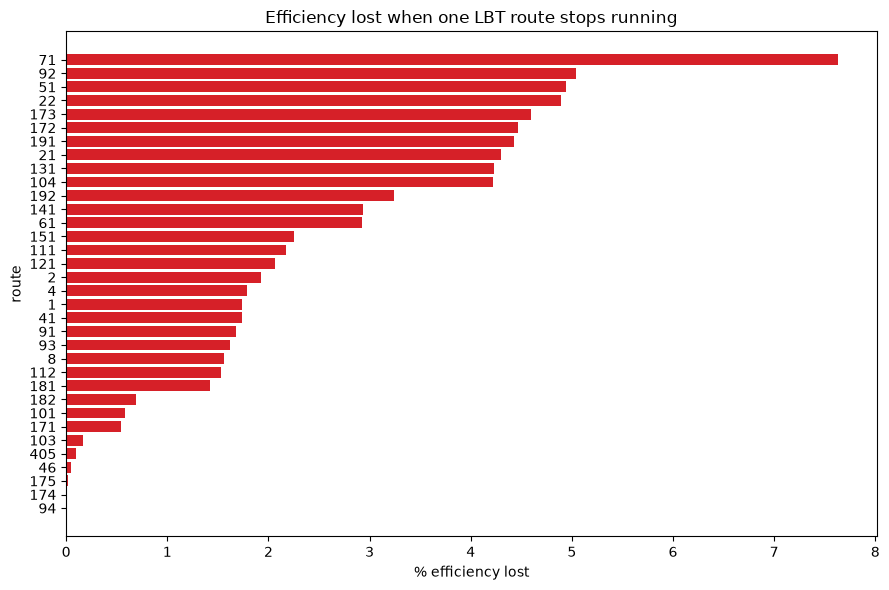

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_df = outages.assign(loss=100 * (1 - outages["efficiency_rel"])).sort_values("loss")
ax.barh(plot_df["route"], plot_df["loss"], color="#D62028")
ax.set(title="Efficiency lost when one LBT route stops running", xlabel="% efficiency lost", ylabel="route")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_route_outages.png", dpi=150)

## 4. How much does the walking radius matter?

Week 2 found that walking transfers are what keep the directed network connected. Rebuild the graph with 100, 200 and 400 m walking radii and rerun the betweenness attack.

In [9]:
%%time
lbt = {"lbt": load_feed(ROOT / "data" / "raw" / "lbt", "20261104")}
radius_curves, radius_summary = [], {}
for radius in [100, 200, 400]:
    Gr = build_graph(lbt, walk_radius_m=radius)
    radius_summary[f"{radius} m"] = graph_summary(Gr)
    radius_curves.append(attack_curve(Gr, "betweenness", FRACTIONS).assign(radius=radius))
radius_curves = pd.concat(radius_curves)
pd.DataFrame(radius_summary)

CPU times: user 31.5 s, sys: 82.4 ms, total: 31.6 s
Wall time: 11min 36s


,100 m,200 m,400 m
nodes,1853,1853,1853
transit edges,1990,1990,1990
walk edges,2341,3890,10800
weakly connected components,1,1,1
largest weak component share,1.0,1.0,1.0
strongly connected components,1,1,1
largest strong component share,1.0,1.0,1.0
mean out-degree,2.34,3.17,6.9


fraction,0.04,0.10,0.20
radius,,,
100,0.815,0.603,0.357
200,0.827,0.627,0.397
400,0.846,0.666,0.464


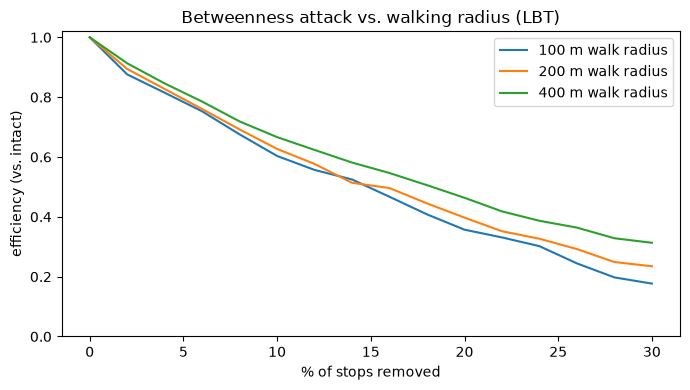

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for radius, df in radius_curves.groupby("radius"):
    ax.plot(df["fraction"] * 100, df["efficiency_rel"], label=f"{radius} m walk radius")
ax.set(title="Betweenness attack vs. walking radius (LBT)", xlabel="% of stops removed",
       ylabel="efficiency (vs. intact)", ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "lbt_walk_radius_sensitivity.png", dpi=150)
radius_curves.pivot(index="radius", columns="fraction", values="efficiency_rel")[[0.04, 0.1, 0.2]].round(3)

## Findings

**Baseline (LBT, Wed 2026-11-04):** every stop can reach every other stop, and the average fastest trip between two stops is 29 minutes. That figure counts no waiting time; see the limitations in notebook 02.

**1. Random failures hurt about as much as targeting the most connected stops, and more than targeting busy or high-betweenness stops.**

| Strategy (static) | % of stops removed to halve efficiency | Efficiency left at 10% removed |
|---|---|---|
| degree | 9.2% | 0.42 |
| random (mean of 10) | 10.2% | 0.51 |
| betweenness | 15.6% | 0.63 |
| trips_per_day | 19.6% | 0.71 |

Two reasons:
- **Bus routes are chains, and walking rarely bridges a gap.** Consecutive stops are a median 335 m apart, and 85% of them are more than the 200 m walking radius apart. So losing almost any single stop cuts its route there. Random failures spread across the whole network and cut many routes at once.
- **Static rankings pick clusters of neighboring stops.** The top 10 betweenness stops are mostly on one corridor (Cherry Ave at Wardlow/33rd/Spring/36th/37th). The top 10 degree stops are the downtown transit mall bays. Once the first stop in a cluster is gone, removing its neighbors adds little damage. Busy stops (CSULB, downtown) sit in dense areas where riders have alternatives, so removing them hurts least.

**2. Re-ranking after each round makes betweenness the most damaging attack.** The adaptive betweenness attack re-ranks every 2% of stops removed. At 10% removed it leaves 0.45 efficiency, versus 0.63 for the static version; at 20% removed it leaves 0.21 versus 0.40. After each round the remaining traffic shifts onto new paths, and the adaptive attack follows it. Which stops are "critical" depends on what has already failed.

**3. No single route outage is catastrophic.** The worst is route 71, which costs 7.6% of efficiency and leaves 7.3% of stop pairs unreachable. Next come routes 92, 51, and 22, each costing about 5%. Because only segments that route serves alone are removed, shared corridors and walking absorb most of the loss. (`added_min` can be negative because pairs that become unreachable drop out of the average travel time.)

**4. Walking radius changes the numbers but not the story.** A 400 m radius gives about 2.8× as many walk edges as 200 m and leaves 0.46 efficiency at 20% removed under the betweenness attack, versus 0.40 at 200 m and 0.36 at 100 m. The ranking of strategies doesn't depend on this choice.

**What this means for Week 4:** the usual centrality measures are poor proxies for actual damage. Trips/day and betweenness each rank stops very differently from what really breaks the network. This makes the case for the surrogate model: compute the true damage from removing each stop one at a time (1,853 evaluations, about 0.3 s each, roughly 10 minutes) and learn to predict it from cheap features, including chain-related ones like "how far is the nearest stop I could walk to instead?"

_Note: the `%%time` wall times above are inflated because this notebook ran in the background. CPU time is the more meaningful number._